In [4]:
import pandas as pd
from sklearn import datasets
%config InlineBackend.figure_format = 'retina'

In [5]:
cancer = datasets.load_breast_cancer()

In [6]:
print("Features: ", cancer.feature_names)

Features:  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [7]:
print("Labels: ", cancer.target_names)

Labels:  ['malignant' 'benign']


In [8]:
import pandas as pd
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
cancer = datasets.load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.DataFrame (cancer.target, columns=['cancer'])
y['cancer'] = y.cancer.apply(lambda x: 1 if x == 0 else 0)
df = pd.concat([X, y], axis=1)
scaler = StandardScaler()
scaler.fit(X)
X_sca = scaler.transform(X)
X_sca = pd.DataFrame(X_sca, columns=cancer.feature_names)

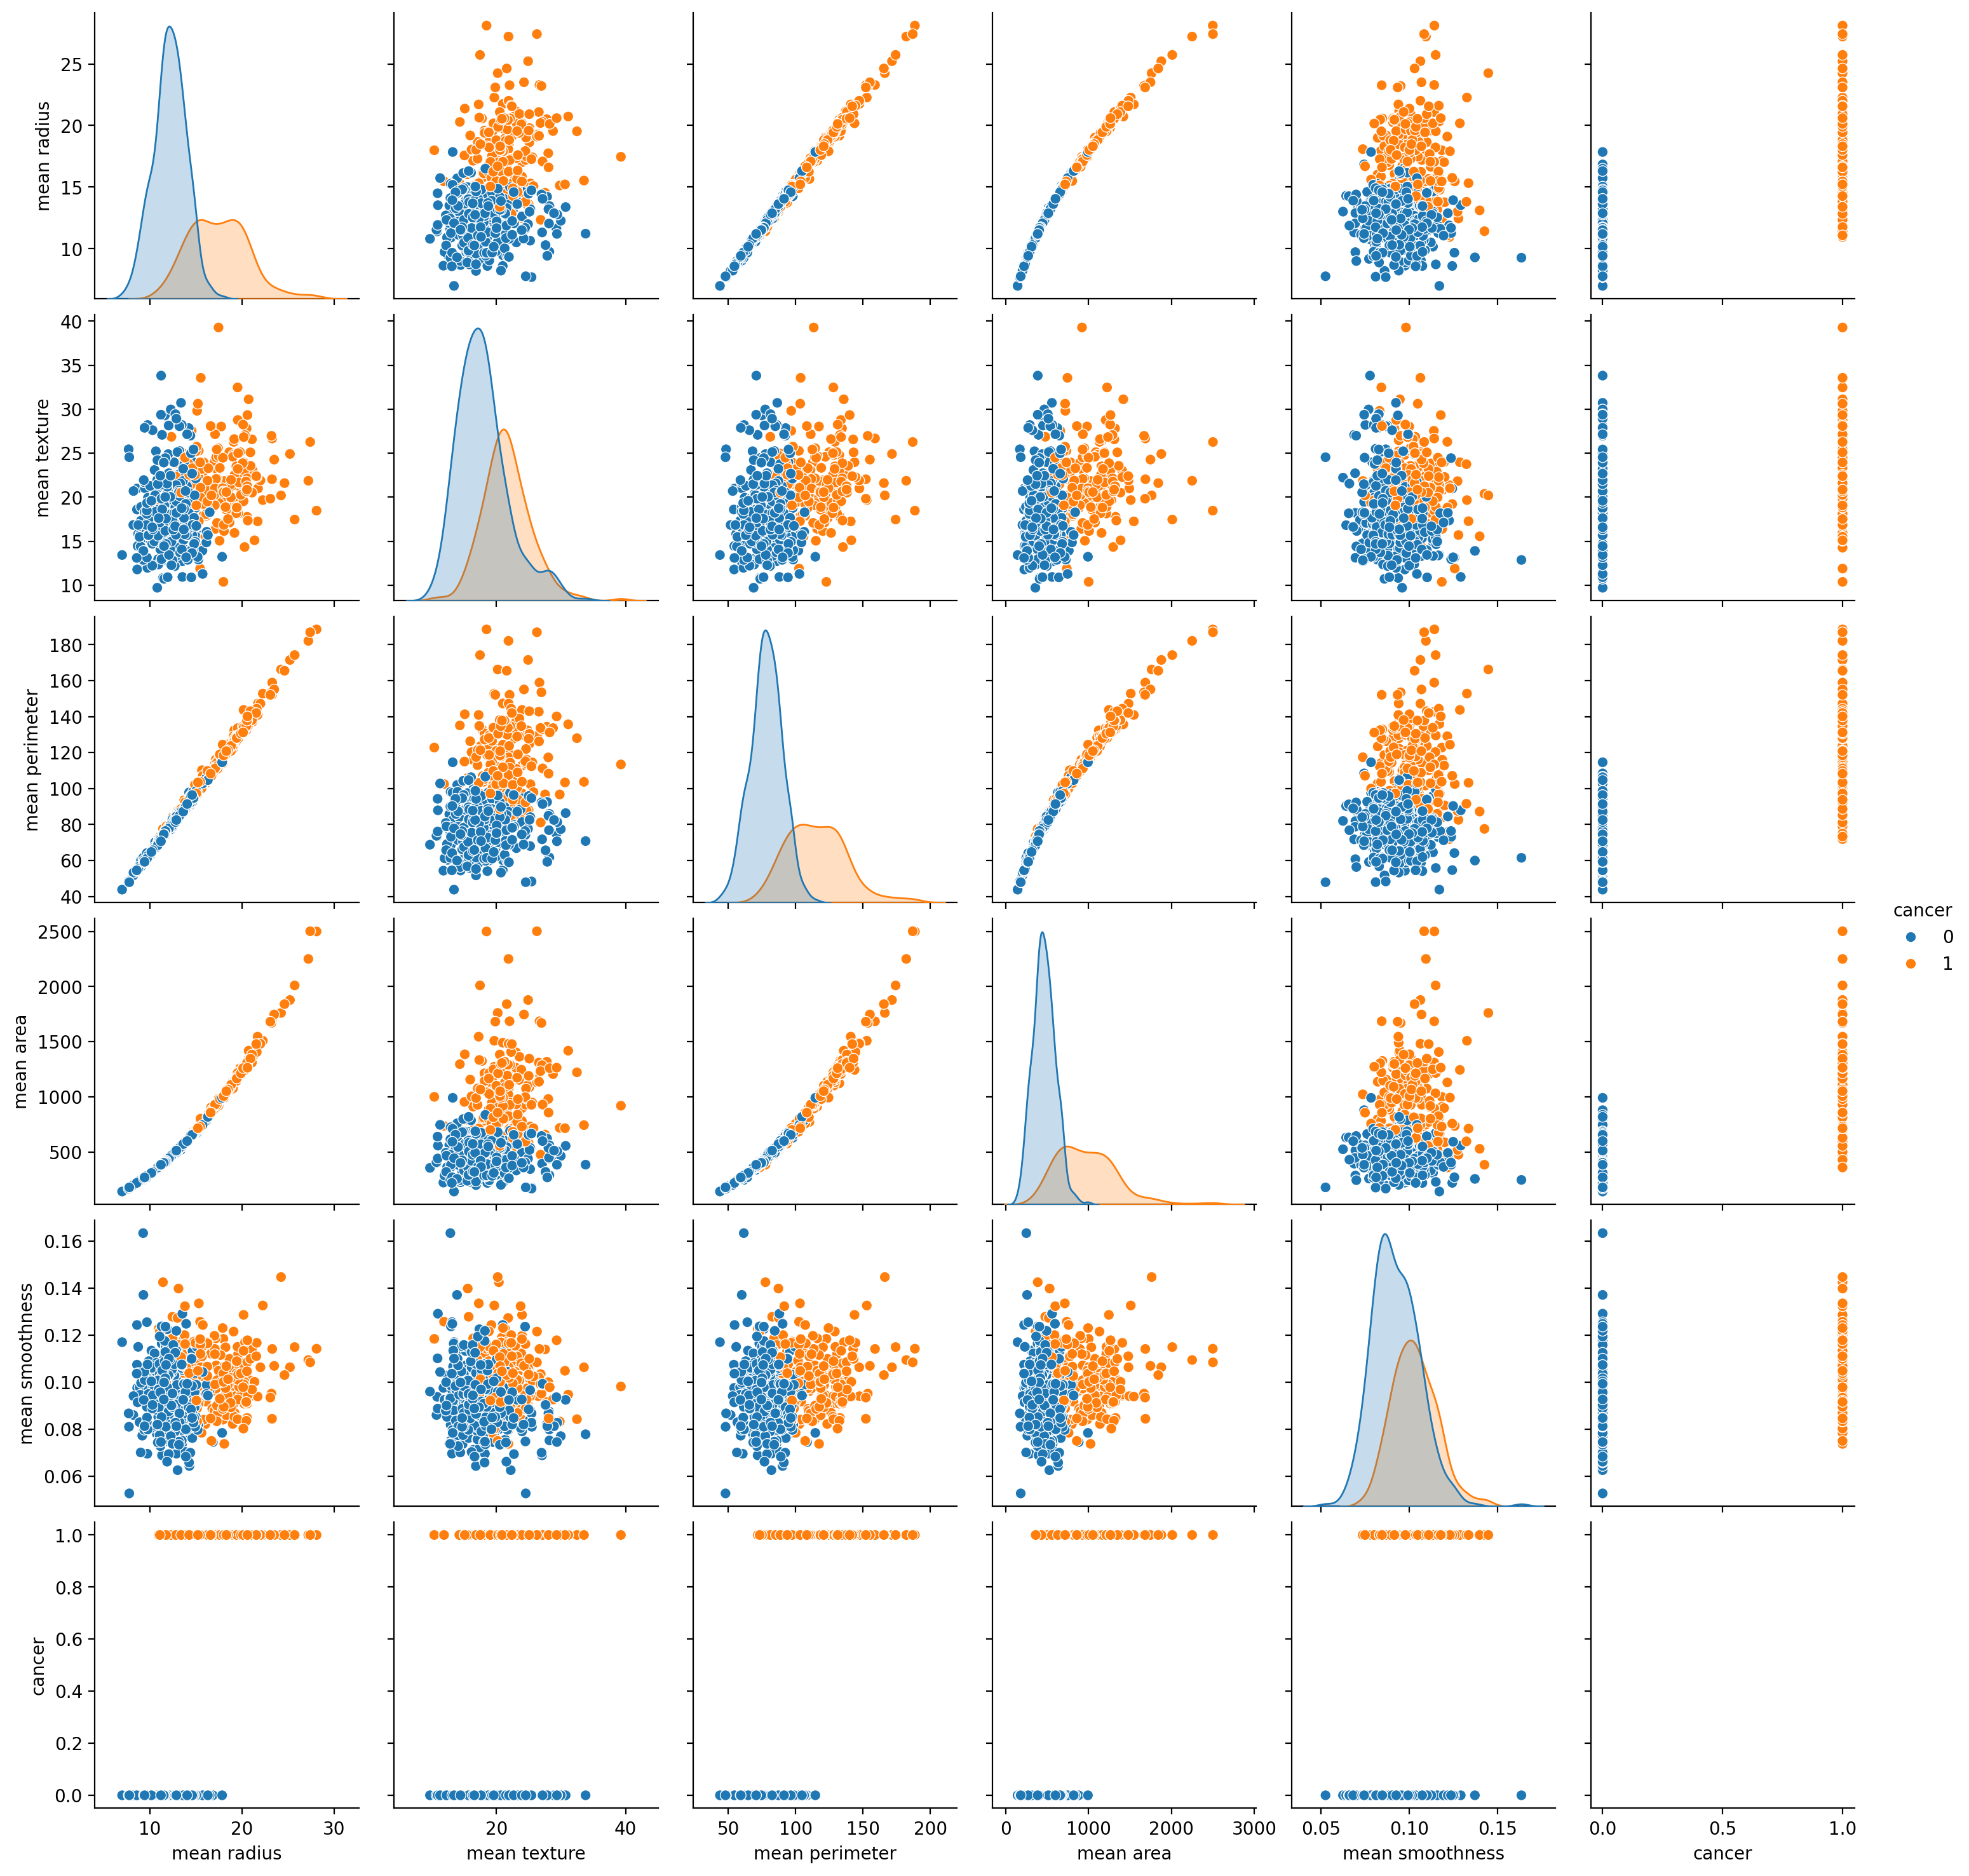

In [9]:

import seaborn as sns
sns.pairplot(df, vars=['mean radius', 'mean texture', 'mean perimeter', 'mean area','mean smoothness', 'cancer'], hue="cancer")

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_sca, y, train_size = .8, random_state = 101)
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)

/Users/napat/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [11]:
from sklearn import metrics
y_pred=model.predict(X_test)
results_df = pd.DataFrame(metrics.confusion_matrix(y_test, y_pred)).rename({0:"Predicted: Benign", 1:"Predicted: Malignant"}, axis="columns")
results_df.rename({0:"Actual: Benign", 1:"Actual: Malignant"}, axis="index")

,Predicted: Benign,Predicted: Malignant
Actual: Benign,72,0
Actual: Malignant,1,41


In [14]:
%pip install statsmodels scikit-learn pandas seaborn matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 87.7 kB/s  0:01:12m0:00:010:04m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [15]:
import statsmodels.api as sm

In [16]:
model_best = sm.Logit(y, X_sca).fit()

Optimization terminated successfully.
         Current function value: 0.023921
         Iterations 19


In [17]:
model_best.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                               Results: Logit
============================================================================
Model:                  Logit               Method:              MLE        
Dependent Variable:     cancer              Pseudo R-squared:    0.964      
Date:                   2026-10-24 23:13    AIC:                 87.2221    
No. Observations:       569                 BIC:                 217.5385   
Df Model:               29                  Log-Likelihood:      -13.611    
Df Residuals:           539                 LL-Null:             -375.72    
Converged:              1.0000              LLR p-value:         8.6176e-134
No. Iterations:         19.0000             Scale:               1.0000     
----------------------------------------------------------------------------
                          Coef.   Std.Err.    z    P>|z|    [0.025   0.975] 
----------------------------------------------------------------------------
mean radius             -287.0824 202.6087 -1.4169 0.1565 -684.1881 110.0234
mean texture               1.9736   3.6147  0.5460 0.5851   -5.1111   9.0583
mean perimeter           155.1279 128.1484  1.2105 0.2261  -96.0384 406.2942
mean area                124.2255 103.6690  1.1983 0.2308  -78.9619 327.4130
mean smoothness           17.7572  11.7794  1.5075 0.1317   -5.3299  40.8443
mean compactness         -47.5162  34.9459 -1.3597 0.1739 -116.0089  20.9766
mean concavity            13.5187  18.6680  0.7242 0.4690  -23.0699  50.1073
mean concave points       15.7509  16.3084  0.9658 0.3341  -16.2129  47.7147
mean symmetry             -7.0581   5.2858 -1.3353 0.1818  -17.4181   3.3020
mean fractal dimension     3.6390   7.7308  0.4707 0.6378  -11.5131  18.7911
radius error               7.5926  35.7278  0.2125 0.8317  -62.4326  77.6177
texture error             -4.6785   4.6374 -1.0089 0.3130  -13.7676   4.4106
perimeter error          -27.3367  22.9867 -1.1892 0.2343  -72.3898  17.7165
area error                72.9286  72.7887  1.0019 0.3164  -69.7346 215.5919
smoothness error           2.0383   3.0429  0.6699 0.5030   -3.9256   8.0022
compactness error         28.8732  19.2535  1.4996 0.1337   -8.8630  66.6093
concavity error          -25.5843  17.5528 -1.4576 0.1450  -59.9871   8.8185
concave points error      27.8933  18.8928  1.4764 0.1398   -9.1358  64.9225
symmetry error            -9.8888   7.4311 -1.3307 0.1833  -24.4536   4.6759
fractal dimension error  -47.2098  32.6963 -1.4439 0.1488 -111.2934  16.8738
worst radius             139.3815 123.2727  1.1307 0.2582 -102.2286 380.9915
worst texture             12.7728   8.2133  1.5551 0.1199   -3.3249  28.8705
worst perimeter           34.3664  43.4392  0.7911 0.4289  -50.7728 119.5056
worst area              -146.7785 131.8767 -1.1130 0.2657 -405.2521 111.6951
worst smoothness         -10.9287  10.3654 -1.0543 0.2917  -31.2445   9.3872
worst compactness        -20.7866  15.2746 -1.3609 0.1736  -50.7243   9.1511
worst concavity           28.5819  19.8617  1.4390 0.1501  -10.3463  67.5102
worst concave points      -5.7206   6.4741 -0.8836 0.3769  -18.4097   6.9684
worst symmetry            15.6530  11.3298  1.3816 0.1671   -6.5529  37.8590
worst fractal dimension   28.1211  19.6431  1.4316 0.1523  -10.3786  66.6208
============================================================================

"""